# K-Means Clustering

### IMport Librabry

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

### Load dataset

In [2]:
df = pd.read_csv("../Dataset/iris.csv")
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


### Dataset Information

In [3]:
df.shape

(150, 5)

In [4]:
df.columns

Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'target'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [6]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [7]:
df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

### Separating Features

In [8]:
X = df.drop(columns=["target"])
print("Features used for clustering:")
print(X.columns.tolist())
print("\nFeature shape:", X.shape)

Features used for clustering:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Feature shape: (150, 4)


### Feature Scaling

In [9]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (150, 4)


### Elbow Method

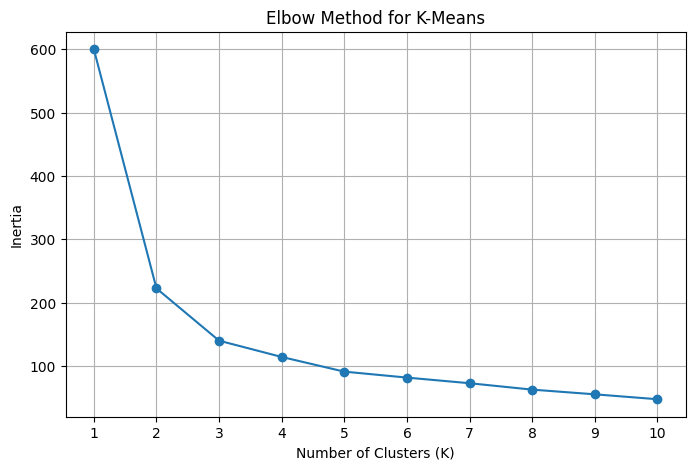

In [10]:
inertias = []
k_values = range(1, 11)
for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

### Silhouette Score

In [11]:
silhouette_scores = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append({
        "K": k,
        "Silhouette Score": score
    })
silhouette_results = pd.DataFrame(silhouette_scores)
silhouette_results

,K,Silhouette Score
0,2,0.581750
1,3,0.459948
2,4,0.386941
3,5,0.345901
4,6,0.317079
5,7,0.320197
6,8,0.338692
7,9,0.342360
8,10,0.351793


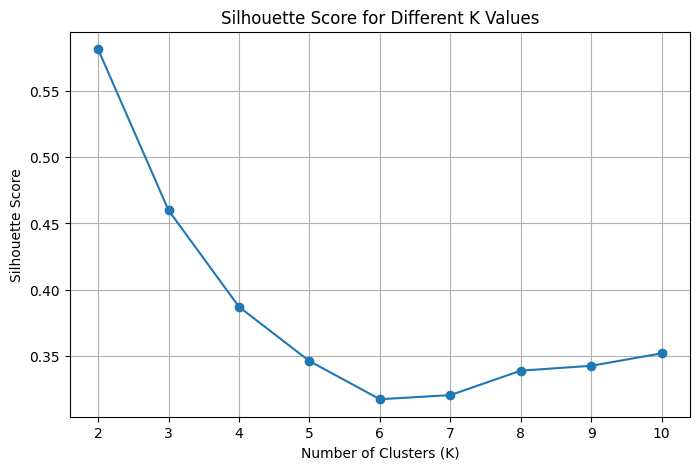

In [12]:
plt.figure(figsize=(8, 5))
plt.plot(silhouette_results["K"], silhouette_results["Silhouette Score"], marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")
plt.xticks(silhouette_results["K"])
plt.grid(True)
plt.show()

## Model Training

In [16]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)
df_results = df.copy()
df_results["Cluster"] = cluster_labels
df_results.tail(10)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,Cluster
140,6.7,3.1,5.6,2.4,2,2
141,6.9,3.1,5.1,2.3,2,2
142,5.8,2.7,5.1,1.9,2,0
143,6.8,3.2,5.9,2.3,2,2
144,6.7,3.3,5.7,2.5,2,2
145,6.7,3.0,5.2,2.3,2,2
146,6.3,2.5,5.0,1.9,2,0
147,6.5,3.0,5.2,2.0,2,2
148,6.2,3.4,5.4,2.3,2,2
149,5.9,3.0,5.1,1.8,2,0


In [17]:
centers_scaled = pd.DataFrame(kmeans.cluster_centers_, columns=X.columns)
centers_scaled

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.050220,-0.883376,0.347738,0.281527
1,-1.014579,0.853263,-1.304987,-1.254893
2,1.135970,0.088422,0.996155,1.017526


In [18]:
centers_original = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=X.columns)
centers_original

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.801887,2.673585,4.369811,1.413208
1,5.006000,3.428000,1.462000,0.246000
2,6.780851,3.095745,5.510638,1.972340


In [19]:
final_silhouette = silhouette_score( X_scaled, cluster_labels)
print("Silhouette Score for K=3:", round(final_silhouette, 4))

Silhouette Score for K=3: 0.4599


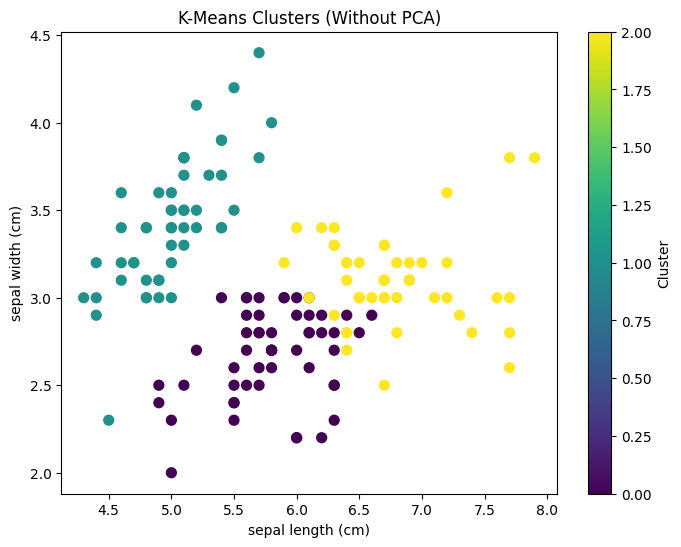

In [20]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X.iloc[:, 0],
    X.iloc[:, 1],
    c=cluster_labels,
    cmap="viridis",
    s=50
)
plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.title("K-Means Clusters (Without PCA)")
plt.colorbar(scatter, label="Cluster")
plt.show()

In [ ]:
pd.crosstab(
    df_results["target"],
    df_results["Cluster"],
    rownames=["Actual Target"],
    colnames=["K-Means Cluster"]
)

K-Means Cluster,0,1,2
Actual Target,,,
0,0,50,0
1,39,0,11
2,14,0,36
